In [1]:
import torch
import torch.nn as nn


class BaselineCNN(nn.Module):
    def __init__(self, channels=(32, 64, 128, 256), dropout=0.3):
        super(BaselineCNN, self).__init__()

        self.blocks = nn.ModuleList()
        in_channels = 3
        for out_channels in channels:
            block = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2),
            )
            self.blocks.append(block)
            in_channels = out_channels

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(channels[len(channels) - 1], 1)

    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x


if __name__ == "__main__":
    model = BaselineCNN()
    fake_images = torch.randn(2, 3, 512, 512)
    output = model(fake_images)
    print(output.shape)

torch.Size([2, 1])


In [2]:
import os
import glob
import pandas as pd
import numpy as np

# Find the preprocessing manifest
manifest_files = glob.glob(
    "/kaggle/input/**/manifest_v2.csv",
    recursive=True
)

if not manifest_files:
    manifest_files = glob.glob(
        "/kaggle/input/**/DR_all.csv",
        recursive=True
    )

print("Manifests found:", manifest_files)

if not manifest_files:
    raise FileNotFoundError("Could not find the dataset manifest.")

MANIFEST = manifest_files[0]
df = pd.read_csv(MANIFEST)

DATASET_DIR = os.path.dirname(MANIFEST)
PROCESSED_DIR = os.path.join(DATASET_DIR, "processed")

print("Dataset directory:", DATASET_DIR)
print("Processed directory:", PROCESSED_DIR)

print("\nManifest:", MANIFEST)
print("Total images:", len(df))

print("\nColumns:")
print(df.columns.tolist())

print("\nSplit counts:")
print(df["split"].value_counts())

print("\nLabel counts:")
print(df["label"].value_counts().sort_index())

print("\nGrade-to-label mapping:")
print(pd.crosstab(df["grade"], df["label"]))

print("\nLabel distribution by split:")
print(pd.crosstab(df["split"], df["label"]))

print("\nSource distribution:")
print(pd.crosstab(df["split"], df["source"]))

print("\nFirst few rows:")
display(df.head())

Manifests found: ['/kaggle/input/notebooks/lohitashwamadhan/02-preprocessing/manifest_v2.csv']
Dataset directory: /kaggle/input/notebooks/lohitashwamadhan/02-preprocessing
Processed directory: /kaggle/input/notebooks/lohitashwamadhan/02-preprocessing/processed

Manifest: /kaggle/input/notebooks/lohitashwamadhan/02-preprocessing/manifest_v2.csv
Total images: 88839

Columns:
['filename', 'path', 'source', 'group_id', 'grade', 'label', 'orig_split', 'split', 'excluded_reason', 'processed_path', 'load_ok']

Split counts:
split
unused    45578
train     30287
test       6491
val        6483
Name: count, dtype: int64

Label counts:
label
0    67148
1    21691
Name: count, dtype: int64

Grade-to-label mapping:
label      0      1
grade              
0      67148      0
1          0   4264
2          0  14152
3          0   1066
4          0   2209

Label distribution by split:
label       0      1
split               
test     4907   1584
train   15126  15161
unused  42223   3355
val      489

,filename,path,source,group_id,grade,label,orig_split,split,excluded_reason,processed_path,load_ok
0,005b95c28852.jpg,/kaggle/input/datasets/ascanipek/eyepacs-aptos...,APTOS,aptos_005b95c28852,0,0,train,unused,trimmed_to_match_ratio,/kaggle/working/processed/unused/005b95c28852.jpg,True
1,0097f532ac9f.jpg,/kaggle/input/datasets/ascanipek/eyepacs-aptos...,APTOS,aptos_0097f532ac9f,0,0,train,train,NaN,/kaggle/working/processed/train/0097f532ac9f.jpg,True
2,00cc2b75cddd.jpg,/kaggle/input/datasets/ascanipek/eyepacs-aptos...,APTOS,aptos_00cc2b75cddd,0,0,train,train,NaN,/kaggle/working/processed/train/00cc2b75cddd.jpg,True
3,00f6c1be5a33.jpg,/kaggle/input/datasets/ascanipek/eyepacs-aptos...,APTOS,aptos_00f6c1be5a33,0,0,train,unused,trimmed_to_match_ratio,/kaggle/working/processed/unused/00f6c1be5a33.jpg,True
4,0125fbd2e791.jpg,/kaggle/input/datasets/ascanipek/eyepacs-aptos...,APTOS,aptos_0125fbd2e791,0,0,train,train,NaN,/kaggle/working/processed/train/0125fbd2e791.jpg,True


In [3]:
print("Processed path column exists:", "processed_path" in df.columns)

if "processed_path" in df.columns:
    print("\nSample processed paths:")
    print(df["processed_path"].head())

    print("\nChecking whether images exist:")
    for path in df["processed_path"].head():
        print(path, "->", os.path.exists(path))

print("\nChecking dataset folder:")
print(os.listdir(os.path.dirname(MANIFEST))[:20])

Processed path column exists: True

Sample processed paths:
0    /kaggle/working/processed/unused/005b95c28852.jpg
1     /kaggle/working/processed/train/0097f532ac9f.jpg
2     /kaggle/working/processed/train/00cc2b75cddd.jpg
3    /kaggle/working/processed/unused/00f6c1be5a33.jpg
4     /kaggle/working/processed/train/0125fbd2e791.jpg
Name: processed_path, dtype: object

Checking whether images exist:
/kaggle/working/processed/unused/005b95c28852.jpg -> False
/kaggle/working/processed/train/0097f532ac9f.jpg -> False
/kaggle/working/processed/train/00cc2b75cddd.jpg -> False
/kaggle/working/processed/unused/00f6c1be5a33.jpg -> False
/kaggle/working/processed/train/0125fbd2e791.jpg -> False

Checking dataset folder:
['__notebook__.ipynb', '__output__.json', '__results__.html', '__results___files', 'custom.css', 'manifest_v2.csv', 'processed']


In [4]:
import os

PROCESSED_DIR = os.path.join(DATASET_DIR, "processed")

# Rebuild paths using the connected preprocessing dataset
df["processed_path"] = df.apply(
    lambda row: os.path.join(
        PROCESSED_DIR,
        row["split"],
        row["filename"]
    ),
    axis=1
)

# Keep only the actual training, validation and test sets
df = df[df["split"].isin(["train", "val", "test"])].copy()

# Check that every image exists
df["file_exists"] = df["processed_path"].apply(os.path.exists)

print("Images by split:")
print(df["split"].value_counts())

print("\nMissing images:", (~df["file_exists"]).sum())
print("All images accessible:", df["file_exists"].all())

print("\nSample paths:")
print(df[["filename", "split", "processed_path", "file_exists"]].head())

Images by split:
split
train    30287
test      6491
val       6483
Name: count, dtype: int64

Missing images: 0
All images accessible: True

Sample paths:
           filename  split                                     processed_path  \
1  0097f532ac9f.jpg  train  /kaggle/input/notebooks/lohitashwamadhan/02-pr...   
2  00cc2b75cddd.jpg  train  /kaggle/input/notebooks/lohitashwamadhan/02-pr...   
4  0125fbd2e791.jpg  train  /kaggle/input/notebooks/lohitashwamadhan/02-pr...   
5  0151781fe50b.jpg  train  /kaggle/input/notebooks/lohitashwamadhan/02-pr...   
7  01f7bb8be950.jpg  train  /kaggle/input/notebooks/lohitashwamadhan/02-pr...   

   file_exists  
1         True  
2         True  
4         True  
5         True  
7         True  


Image format: JPEG
Image size: (512, 512)
Image mode: RGB


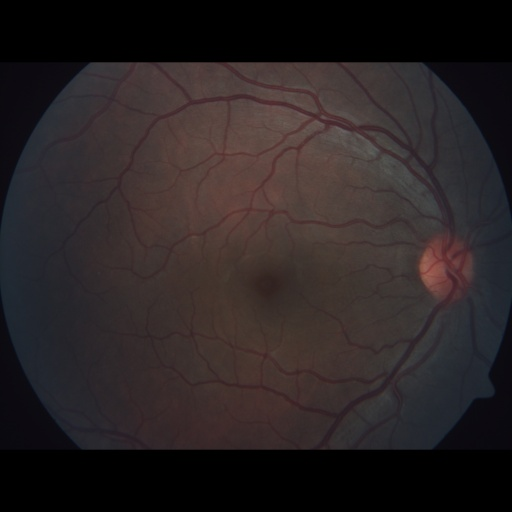

In [5]:
from PIL import Image

sample_path = df[df["split"] == "train"]["processed_path"].iloc[0]

image = Image.open(sample_path)

print("Image format:", image.format)
print("Image size:", image.size)
print("Image mode:", image.mode)

display(image)

In [6]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class RetinalDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["processed_path"]).convert("RGB")
        label = torch.tensor(float(row["label"]), dtype=torch.float32)

        if self.transform:
            image = self.transform(image)

        return image, label


transform = transforms.Compose([
    transforms.ToTensor()
])

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

train_dataset = RetinalDataset(train_df, transform=transform)
val_dataset = RetinalDataset(val_df, transform=transform)
test_dataset = RetinalDataset(test_df, transform=transform)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training samples: 30287
Validation samples: 6483
Test samples: 6491


In [7]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 947
Validation batches: 203
Test batches: 203


In [8]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image pixel range:", images.min().item(), "to", images.max().item())
print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 512, 512])
Label batch shape: torch.Size([32])
Image pixel range: 0.0 to 1.0
Labels: tensor([0., 1., 1., 1., 1., 0., 1., 1., 1., 0.])


In [9]:
import random
import numpy as np
import torch
import torch.nn as nn

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training configuration
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
NUM_EPOCHS = 30
PATIENCE = 5

# Model
model = BaselineCNN().to(device)

# Standard unweighted binary cross-entropy loss
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Device:", device)
print("Model:", model.__class__.__name__)
print("Loss:", criterion)
print("Optimizer:", optimizer)

# Check whether any group appears in more than one split
split_groups = df.groupby("group_id")["split"].nunique()

overlapping_groups = split_groups[split_groups > 1]

print("Unique groups:", df["group_id"].nunique())
print("Groups appearing in multiple splits:", len(overlapping_groups))

if len(overlapping_groups) > 0:
    print("\nExamples:")
    print(overlapping_groups.head())
else:
    print("No group overlap between splits.")

print("\nClass distribution:")
print(pd.crosstab(df["split"], df["label"]))

print("\nGrade-to-label mapping:")
print(pd.crosstab(df["grade"], df["label"]))

Device: cuda
Model: BaselineCNN
Loss: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Unique groups: 29089
Groups appearing in multiple splits: 0
No group overlap between splits.

Class distribution:
label      0      1
split              
test    4907   1584
train  15126  15161
val     4892   1591

Grade-to-label mapping:
label      0      1
grade              
0      24925      0
1          0   3619
2          0  11961
3          0    888
4          0   1868


In [10]:
# Use 10% of training data for debugging
train_sample = train_df.sample(frac=0.1, random_state=42)

sample_dataset = RetinalDataset(
    train_sample,
    transform=transform
)

sample_loader = DataLoader(
    sample_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

print("Sample training images:", len(sample_dataset))
print("Sample batches:", len(sample_loader))

Sample training images: 3029
Sample batches: 95


In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
NUM_EPOCHS = 30
PATIENCE = 5

model = BaselineCNN().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Device:", device)
print("Model:", model.__class__.__name__)
print("Loss:", criterion)
print("Optimizer:", optimizer)

Device: cuda
Model: BaselineCNN
Loss: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [12]:
val_sample = val_df.sample(n=500, random_state=42)

val_sample_dataset = RetinalDataset(
    val_sample,
    transform=transform
)

val_sample_loader = DataLoader(
    val_sample_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Debug validation images:", len(val_sample_dataset))

Debug validation images: 500


In [13]:
from sklearn.metrics import roc_auc_score, confusion_matrix
import numpy as np
import torch

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images).squeeze(1)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    return running_loss / len(loader.dataset)


def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images).squeeze(1)
            loss = criterion(logits, labels)

            probs = torch.sigmoid(logits)

            running_loss += loss.item() * images.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)

    val_loss = running_loss / len(loader.dataset)
    auc = roc_auc_score(all_labels, all_probs)

    predictions = (all_probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        all_labels, predictions, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0

    return val_loss, auc, sensitivity, specificity

In [14]:
best_auc = 0.0
patience = 5
epochs_without_improvement = 0

best_model_state = None

for epoch in range(NUM_EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_auc, sensitivity, specificity = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation AUROC: {val_auc:.4f}")
    print(f"Sensitivity: {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")

    if val_auc > best_auc:
        best_auc = val_auc
        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        epochs_without_improvement = 0

        print("New best AUROC!")
    else:
        epochs_without_improvement += 1
        print(
            f"No improvement: "
            f"{epochs_without_improvement}/{patience}"
        )

    print("-" * 40)

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

if best_model_state is not None:
    model.load_state_dict(best_model_state)

print(f"Best validation AUROC: {best_auc:.4f}")

Epoch 1/30
Training Loss: 0.6910
Validation Loss: 0.6494
Validation AUROC: 0.5765
Sensitivity: 0.3570
Specificity: 0.7535
New best AUROC!
----------------------------------------
Epoch 2/30
Training Loss: 0.6869
Validation Loss: 0.6678
Validation AUROC: 0.5895
Sensitivity: 0.4915
Specificity: 0.6061
New best AUROC!
----------------------------------------
Epoch 3/30
Training Loss: 0.6845
Validation Loss: 0.6432
Validation AUROC: 0.5714
Sensitivity: 0.3891
Specificity: 0.6958
No improvement: 1/5
----------------------------------------
Epoch 4/30
Training Loss: 0.6834
Validation Loss: 0.7576
Validation AUROC: 0.5770
Sensitivity: 0.8510
Specificity: 0.2018
No improvement: 2/5
----------------------------------------
Epoch 5/30
Training Loss: 0.6815
Validation Loss: 0.8022
Validation AUROC: 0.5904
Sensitivity: 0.8680
Specificity: 0.1874
New best AUROC!
----------------------------------------
Epoch 6/30
Training Loss: 0.6809
Validation Loss: 0.8176
Validation AUROC: 0.5982
Sensitivity: 0.